In [1]:
import metrics as m
import networkx as nx
import matplotlib.pyplot as plt
from Graph import G
import powerlaw as pl
import numpy as np


DiGraph with 498 nodes and 10373 edges


1.1 Rozkład stopni wejściowych i wyjściowych

{'nodes': 498, 'edges': 10373, 'density': 0.041910095108805445, 'directed': True}


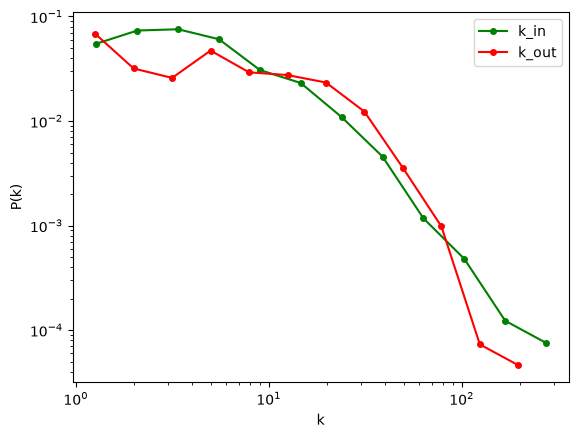

In [46]:
print(m.basic_info(G))
k_in, k_out = m.degree_list(G)
k_in_filtered = m.positive_only(k_in)
k_out_filtered = m.positive_only(k_out)

binned_k_in = m.log_binning(k_in_filtered, 13)
binned_k_out = m.log_binning(k_out_filtered, 13)

ax_k = m.plot_loglog(binned_k_in, xlabel="k", ylabel="P(k)", label="k_in", color="green")
m.plot_loglog(binned_k_out, ax=ax_k, xlabel="k", ylabel="P(k)", label="k_out", color="red")
plt.show()


In [3]:
fit_in = pl.Fit(k_in_filtered, discrete=True)
print("k_in: alpha =", fit_in.alpha, "xmin =", fit_in.xmin)

R1, p1 = fit_in.distribution_compare("power_law", "truncated_power_law")
print("R1:", R1, "p1:", p1)
R2, p2 = fit_in.distribution_compare("power_law", "lognormal")
print("R2:", R2, "p2:", p2)


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 76/76 [00:00<00:00, 2364.04it/s]

k_in: alpha = 2.4575604013882413 xmin = 24.0


R1: -0.8787346348420022 p1: 0.18494048972797295
R2: -0.4298557656123232 p2: 0.5066199467182247


c:\Users\lenar\Desktop\studia\VS\inzynierka\.venv\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')


In [4]:
fit_out = pl.Fit(k_out_filtered, discrete=True)
print("k_out: alpha =", fit_out.alpha, "xmin =", fit_out.xmin)

R3, p3 = fit_out.distribution_compare("power_law", "truncated_power_law")
print("R1:", R3, "p1:", p3)
R4, p4 = fit_out.distribution_compare("power_law", "lognormal")
print("R2:", R4, "p2:", p4)

print("Alpha truncated power law:", fit_out.truncated_power_law.alpha)
print("Xmin truncated power law:", fit_out.truncated_power_law.xmin)

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 75/75 [00:00<00:00, 912.54it/s]


k_out: alpha = 2.8881799874538467 xmin = 22.0
R1: -2.311329944124851 p1: 0.03155227372195435
R2: -2.6226495079861465 p2: 0.21348018426996596
Alpha truncated power law: 2.126219682213355
Xmin truncated power law: 22.0


In [5]:
print(sum(k >= fit_in.xmin for k in k_in_filtered))
print(sum(k >= fit_out.xmin for k in k_out_filtered))

119
178


1.2 Rozkład sił węzłów

In [6]:
s_in_pos, s_out_pos = m.strength_list(G, weight='pos')
s_in_neg, s_out_neg = m.strength_list(G, weight='neg')
s_in_neu, s_out_neu = m.strength_list(G, weight='neu')
s_in_weight, s_out_weight = m.strength_list(G, weight='weight')

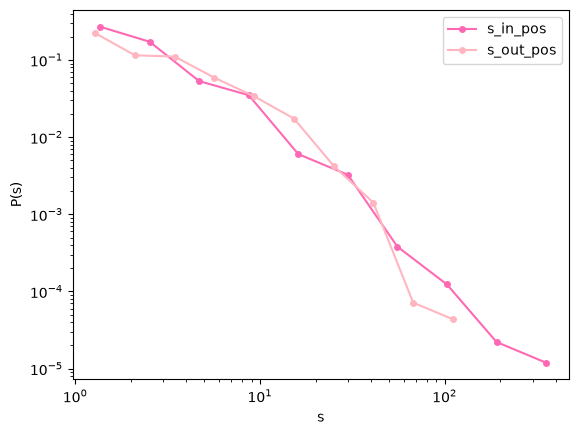

In [7]:
s_in_pos_filtered = m.positive_only(s_in_pos)
s_out_pos_filtered = m.positive_only(s_out_pos)

binned_s_in_pos = m.log_binning(s_in_pos_filtered, 11)
binned_s_out_pos = m.log_binning(s_out_pos_filtered, 11)    

ax_s_pos = m.plot_loglog(binned_s_in_pos, xlabel="s", ylabel="P(s)", label="s_in_pos", color="hotpink")
ax_s_pos = m.plot_loglog(binned_s_out_pos, ax=ax_s_pos, xlabel="s", ylabel="P(s)", label="s_out_pos", color="lightpink")

In [8]:
fit_s_in_pos = pl.Fit(s_in_pos_filtered, discrete=True)
fit_s_out_pos = pl.Fit(s_out_pos_filtered, discrete=True)

print("s_in_pos: alpha =", fit_s_in_pos.alpha, "xmin =", fit_s_in_pos.xmin, "suma obserwacji:", sum(s >= fit_s_in_pos.xmin for s in s_in_pos_filtered))
print("s_out_pos: alpha =", fit_s_out_pos.alpha, "xmin =", fit_s_out_pos.xmin, "suma obserwacji:", sum(s >= fit_s_out_pos.xmin for s in s_out_pos_filtered))

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 40/40 [00:00<00:00, 2607.30it/s]


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 40/40 [00:00<00:00, 932.81it/s]

s_in_pos: alpha = 2.294898781949884 xmin = 7.0 suma obserwacji: 128
s_out_pos: alpha = 2.8584368198738153 xmin = 11.0 suma obserwacji: 110


In [9]:
R1_s, p1_s = fit_s_in_pos.distribution_compare("power_law", "truncated_power_law")
print("R1_s:", R1_s, "p1_s:", p1_s)
R2_s, p2_s = fit_s_in_pos.distribution_compare("power_law", "lognormal")
print("R2_s:", R2_s, "p2_s:", p2_s)

R1_s: -0.0907128807825921 p1_s: 0.6701508159813835
R2_s: -0.03533970784356999 p2_s: 0.8725366738378545


c:\Users\lenar\Desktop\studia\VS\inzynierka\.venv\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')


In [10]:
R3_s, p3_s = fit_s_out_pos.distribution_compare("power_law", "truncated_power_law")
print("R3_s:", R3_s, "p3_s:", p3_s) 
R4_s, p4_s = fit_s_out_pos.distribution_compare("power_law", "lognormal")
print("R4_s:", R4_s, "p4_s:", p4_s)

c:\Users\lenar\Desktop\studia\VS\inzynierka\.venv\Lib\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


R3_s: -1.1374475191569262 p3_s: 0.13148402636132406
R4_s: -1.1393070289779326 p4_s: 0.4096542487246466


<Axes: xlabel='s', ylabel='P(s)'>

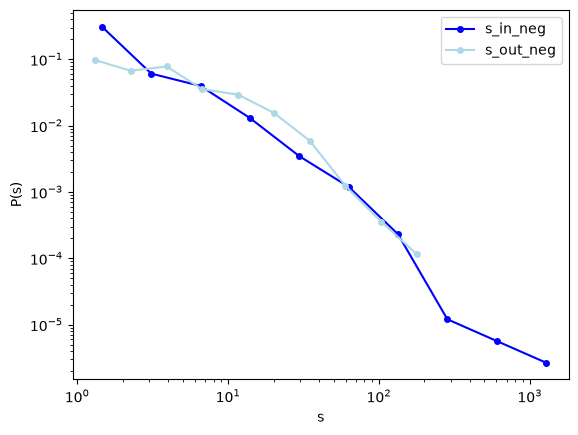

In [11]:
s_in_neg_filtered = m.positive_only(s_in_neg)
s_out_neg_filtered = m.positive_only(s_out_neg)

binned_s_in_neg = m.log_binning(s_in_neg_filtered, 11)
binned_s_out_neg = m.log_binning(s_out_neg_filtered, 11)    

ax_s_neg = m.plot_loglog(binned_s_in_neg, xlabel="s", ylabel="P(s)", label="s_in_neg", color="blue")
m.plot_loglog(binned_s_out_neg, ax=ax_s_neg, xlabel="s", ylabel="P(s)", label="s_out_neg", color="lightblue")

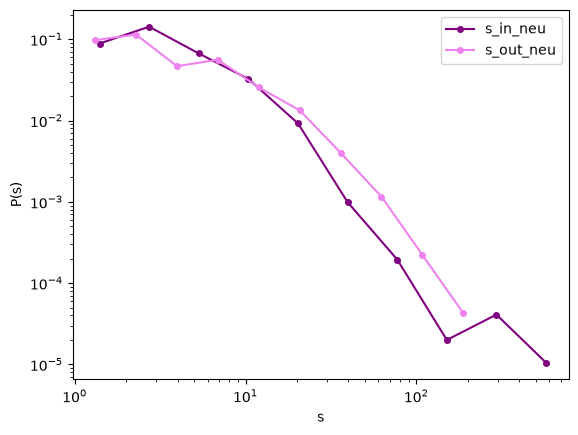

In [12]:
s_in_neu_filtered = m.positive_only(s_in_neu)
s_out_neu_filtered = m.positive_only(s_out_neu)

binned_s_in_neu = m.log_binning(s_in_neu_filtered, 11)
binned_s_out_neu = m.log_binning(s_out_neu_filtered, 11)    

ax_s_neu = m.plot_loglog(binned_s_in_neu, xlabel="s", ylabel="P(s)", label="s_in_neu", color="purple")
ax_s_neu = m.plot_loglog(binned_s_out_neu, ax=ax_s_neu, xlabel="s", ylabel="P(s)", label="s_out_neu", color="violet")

<Axes: xlabel='s', ylabel='P(s)'>

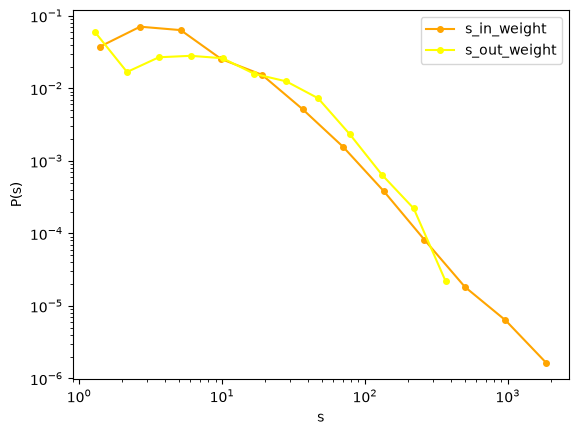

In [47]:
s_in_weight_filtered = m.positive_only(s_in_weight)
s_out_weight_filtered = m.positive_only(s_out_weight)

binned_s_in_weight = m.log_binning(s_in_weight_filtered, 13)
binned_s_out_weight = m.log_binning(s_out_weight_filtered, 13)

ax_s_weight = m.plot_loglog(binned_s_in_weight, xlabel="s", ylabel="P(s)", label="s_in_weight", color="orange")
m.plot_loglog(binned_s_out_weight, ax=ax_s_weight, xlabel="s",  ylabel="P(s)", label="s_out_weight", color="yellow")

In [61]:
print("wartość wykładnika")
for name, binned in [("sin_p", binned_s_in_pos), ("sout_p", binned_s_out_pos),
                     ("sin_neg", binned_s_in_neg), ("sout_neg", binned_s_out_neg),
                     ("sin_neu", binned_s_in_neu), ("sout_neu", binned_s_out_neu),
                     ("sin", binned_s_in_weight), ("sout", binned_s_out_weight)]:
    slope, err, r2, _ = m.linear_regression_loglog(binned)
    print(name, round(-slope, 2), "+/-", round(err, 2))

wartość wykładnika
sin_p 1.94 +/- 0.09
sout_p 1.94 +/- 0.22
sin_neg 1.8 +/- 0.1
sout_neg 1.38 +/- 0.16
sin_neu 1.78 +/- 0.16
sout_neu 1.54 +/- 0.18
sin 1.56 +/- 0.13
sout 1.15 +/- 0.18


1.3 Relacja stopnień-siła

<Axes: xlabel='k', ylabel='average s'>

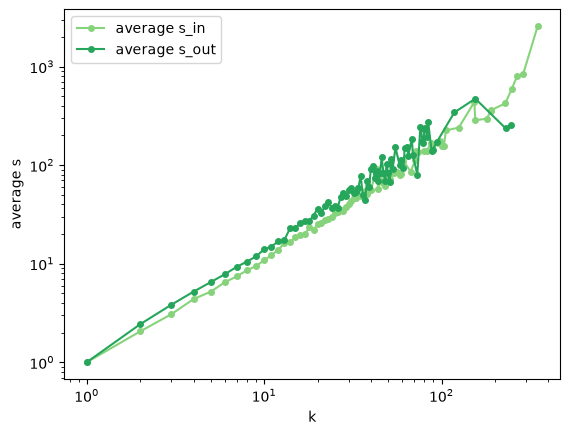

In [14]:
pairs_in, pairs_out = m.degree_strength_pairs(G, weight='weight')

average_in = m.average_strength_per_degree(pairs_in)
average_out = m.average_strength_per_degree(pairs_out)

# print(average_in[:3])
# wykres bez binowania
ax_avg = m.plot_loglog(average_in, xlabel="k", ylabel="average s", label="average s_in", color="#87D37C")
m.plot_loglog(average_out, ax=ax_avg, xlabel="k", ylabel="average s", label="average s_out", color="#26A65B")


In [15]:
binned_in = m.binned_average_strength(pairs_in, 15)
binned_out = m.binned_average_strength(pairs_out, 15)
ks = [k for k, s in binned_in]

# ax_avg_bin = m.plot_loglog(binned_in, xlabel="k", ylabel="⟨s⟩", label="⟨s_in⟩", color="#87D37C")
# m.plot_loglog(binned_out, ax=ax_avg_bin, xlabel="k", ylabel="⟨s⟩", label="⟨s_out⟩", color="#27AE60")

# ax_avg_bin.plot(ks, ks, '--', color='gray', label='B = 1')
# ax_avg_bin.legend()


In [16]:
slope_in, error_in, r_squared_in, intercept_in = m.linear_regression_loglog(binned_in)
slope_out, error_out, r_squared_out, intercept_out = m.linear_regression_loglog(binned_out)
print("Slope in:", slope_in, "Error in:", error_in, "R^2 in:", r_squared_in)
print("Slope out:", slope_out, "Error out:", error_out, "R^2 out:", r_squared_out)

Slope in: 1.1426425179763222 Error in: 0.01396174888348032 R^2 in: 0.9983603962065097
Slope out: 1.1676545178362077 Error out: 0.012635233018404968 R^2 out: 0.9988304210476625


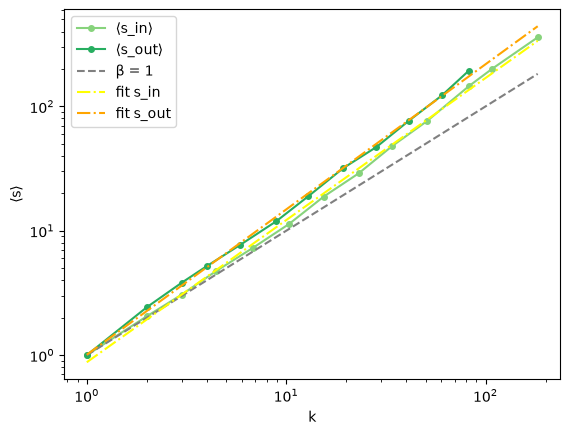

In [17]:
ks = np.array(ks)
k_fit = np.logspace(np.log10(ks.min()), np.log10(ks.max()), 100)
s_fit_in = 10**intercept_in * k_fit**slope_in
s_fit_out = 10**intercept_out * k_fit**slope_out

ax_avg_bin = m.plot_loglog(binned_in, xlabel="k", ylabel="⟨s⟩", label="⟨s_in⟩", color="#87D37C")
m.plot_loglog(binned_out, ax=ax_avg_bin, xlabel="k", ylabel="⟨s⟩", label="⟨s_out⟩", color="#27AE60")
ax_avg_bin.plot(ks, ks, '--', color='gray', label='β = 1')

ax_avg_bin.plot(k_fit, s_fit_in, '-.', color='yellow', label='fit s_in')
ax_avg_bin.plot(k_fit, s_fit_out, '-.', color='orange', label='fit s_out')
ax_avg_bin.legend()
plt.show()

1.4 Rozkład wag krawędzi

In [30]:
all_w = m.edge_weights(G, weight='weight')
pos_w = m.edge_weights(G, weight='pos')
neg_w = m.edge_weights(G, weight='neg') 
neu_w = m.edge_weights(G, weight='neu')

all_w_filtred = m.positive_only(all_w)
pos_w_filtred = m.positive_only(pos_w)
neg_w_filtred = m.positive_only(neg_w)
neu_w_filtred = m.positive_only(neu_w)

print("niezerowa liczba krawędzi dla")
print("all: ", len(all_w_filtred))
print("pos: ", len(pos_w_filtred))
print("neg: ", len(neg_w_filtred))
print("neu: ", len(neu_w_filtred))

print(len(all_w), min(all_w), max(all_w)) # ilosc krawego sie zgadza:)
print(sum(x == 1 for x in all_w)/len(all_w)) #ulamek krawedzi o wadze 1
print(sum( x <= 2 for x in all_w)/len(all_w)) # ulamek krawedzi 1 i 2

niezerowa liczba krawędzi dla
all:  10373
pos:  2462
neg:  4162
neu:  5006
10373 1 89
0.7238985828593464
0.868697580256435


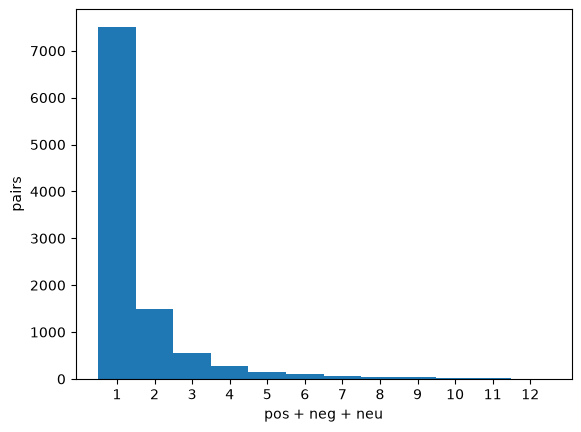

suma pominietych par w goonie waga > 12:  91


In [28]:
fig, ax_all_w = plt.subplots()
ax_all_w.hist(all_w, bins=np.arange(0.5, 13.5, 1))
ax_all_w.set_xticks(range(1, 13))
ax_all_w.set_xlabel("pos + neg + neu")
ax_all_w.set_ylabel("pairs")
plt.show()

print("suma pominietych par w goonie waga > 12: ", sum(x > 12 for x in all_w))

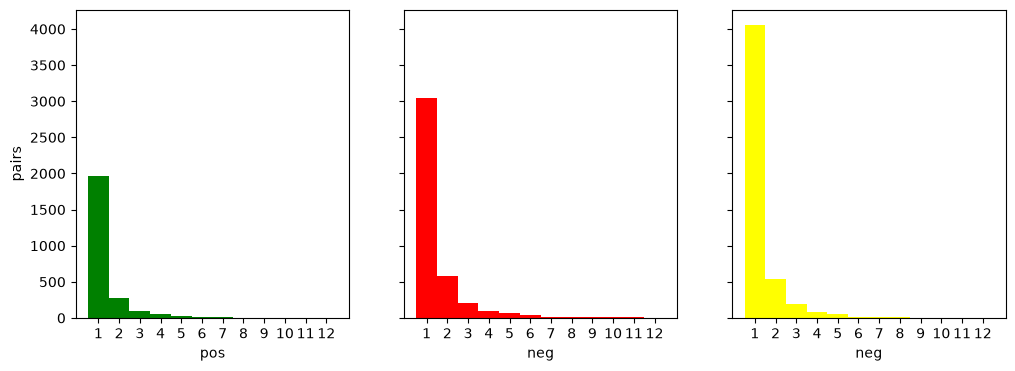

suma pominietych par w ogonie pos, waga > 12:  8
suma pominietych par w ogonie neg, waga > 12:  57
suma pominietych par w ogonie neu, waga > 12:  8


In [44]:
fig, ax_weights = plt.subplots(1, 3, sharey = True, figsize=(12,4))
ax_weights[0].hist(pos_w_filtred, bins=np.arange(0.5, 13.5, 1), color = "green")
ax_weights[0].set_xlabel("pos")
ax_weights[0].set_ylabel("pairs")
ax_weights[0].set_xticks(range(1, 13))

ax_weights[1].hist(neg_w_filtred, bins=np.arange(0.5, 13.5, 1), color = "red")
ax_weights[1].set_xlabel("neg")
# ax_weights[1].set_ylabel("pairs")
ax_weights[1].set_xticks(range(1, 13))

ax_weights[2].hist(neu_w_filtred, bins=np.arange(0.5, 13.5, 1), color = "yellow")
ax_weights[2].set_xlabel("neg")
# ax_weights[2].set_ylabel("pairs")
ax_weights[2].set_xticks(range(1, 13))

plt.show()
print("suma pominietych par w ogonie pos, waga > 12: ", sum(x > 12 for x in pos_w_filtred))
print("suma pominietych par w ogonie neg, waga > 12: ", sum(x > 12 for x in neg_w_filtred))
print("suma pominietych par w ogonie neu, waga > 12: ", sum(x > 12 for x in neu_w_filtred))

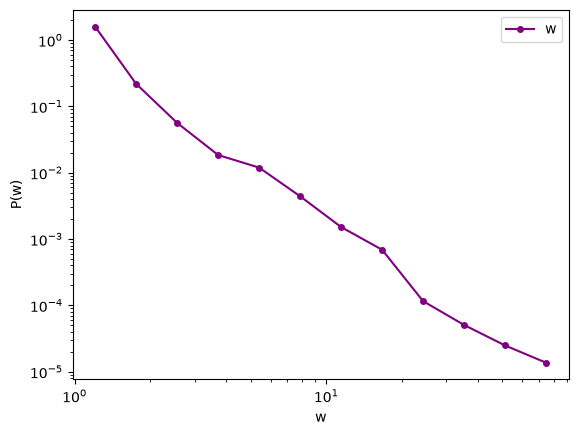

In [59]:
binned_w = m.log_binning(all_w, 13)
ax_w = m.plot_loglog(binned_w, xlabel="w", ylabel="P(w)", label="w", color = "purple")
plt.show()

<Axes: xlabel='w', ylabel='P(w)'>

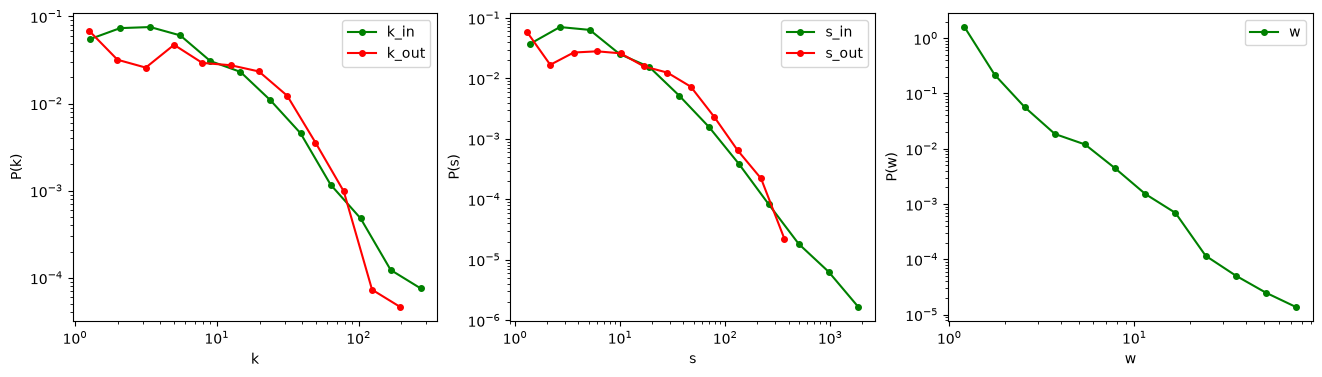

In [67]:
fig, ax_all = plt.subplots(1, 3, figsize=(16,4))
m.plot_loglog(binned_k_in, ax_all[0], xlabel="k", ylabel="P(k)", label= "k_in", color="green")
m.plot_loglog(binned_k_out, ax_all[0], xlabel="k", ylabel="P(k)", label= "k_out", color="red")
m.plot_loglog(binned_s_in_weight, ax_all[1], xlabel="s", ylabel="P(s)", label= "s_in", color="green")
m.plot_loglog(binned_s_out_weight, ax_all[1], xlabel="s", ylabel="P(s)", label= "s_out", color="red")
m.plot_loglog(binned_w, ax_all[2], xlabel="w", ylabel="P(w)", label= "w", color="green")

In [ ]:

print("wartość wykładnika")
for name, binned in [("kin", binned_k_in), ("kout", binned_k_out),
                     ("sin", binned_s_in_weight), ("sout", binned_s_out_weight),
                     ("w", binned_w)]:
    slope, err, r2, _ = m.linear_regression_loglog(binned)
    print(name, round(-slope, 2), "+/-", round(err, 2))

wartość wykładnika
kin 1.37 +/- 0.14
kout 1.32 +/- 0.23
sin 1.56 +/- 0.13
sout 1.15 +/- 0.18
w 2.74 +/- 0.1
